In [1]:

import os

# List attached Kaggle datasets
print("Datasets in Kaggle input:")
print(os.listdir("/kaggle/input"))

# Display folder and file structure
for root, dirs, files in os.walk("/kaggle/input"):
    level = root.replace("/kaggle/input", "").count(os.sep)

    if level <= 4:
        print("  " * level + os.path.basename(root) + "/")

        for file in files[:5]:
            print("  " * (level + 1) + file)


Datasets in Kaggle input:
['datasets']
input/
  datasets/
    aayushisharma13/
      cnn-dataset/
        afhq/


In [2]:

import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
GPU available: True
GPU: Tesla T4


In [3]:

import os

DATASET_PATH = "/kaggle/input/datasets/aayushisharma13/cnn-dataset/afhq"

print("Dataset exists:", os.path.exists(DATASET_PATH))
print("\nFolder structure:\n")

for root, dirs, files in os.walk(DATASET_PATH):
    level = root.replace(DATASET_PATH, "").count(os.sep)

    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")
        for file in files[:3]:
            print("  " * (level + 1) + file)

print("\nTop-level folders:", os.listdir(DATASET_PATH))


Dataset exists: True

Folder structure:

afhq/
  train/
    cat/
      flickr_cat_000002.jpg
      flickr_cat_000003.jpg
      flickr_cat_000004.jpg
    dog/
      flickr_dog_000002.jpg
      flickr_dog_000003.jpg
      flickr_dog_000004.jpg
    wild/
      flickr_wild_000002.jpg
      flickr_wild_000003.jpg
      flickr_wild_000005.jpg
  val/
    cat/
      flickr_cat_000008.jpg
      flickr_cat_000011.jpg
      flickr_cat_000016.jpg
    dog/
      flickr_dog_000043.jpg
      flickr_dog_000045.jpg
      flickr_dog_000054.jpg
    wild/
      flickr_wild_000004.jpg
      flickr_wild_000012.jpg
      flickr_wild_000017.jpg

Top-level folders: ['train', 'val']


In [4]:

from collections import Counter

extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

image_counts = Counter()

for root, dirs, files in os.walk(DATASET_PATH):
    images = [f for f in files if f.lower().endswith(extensions)]

    if images:
        class_name = os.path.basename(root)
        image_counts[class_name] += len(images)

print("Image counts:")
for class_name, count in image_counts.items():
    print(f"{class_name}: {count} images")

print("Total images:", sum(image_counts.values()))


Image counts:
cat: 5653 images
dog: 5239 images
wild: 5238 images
Total images: 16130


In [5]:

import os
import copy
import time
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset

import torchvision
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATASET_PATH = "/kaggle/input/datasets/aayushisharma13/cnn-dataset/afhq"

TRAIN_PATH = os.path.join(DATASET_PATH, "train")
TEST_PATH = os.path.join(DATASET_PATH, "val")

print("Device:", DEVICE)
print("Dataset:", DATASET_PATH)
print("PyTorch:", torch.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
Dataset: /kaggle/input/datasets/aayushisharma13/cnn-dataset/afhq
PyTorch: 2.11.0+cu130
GPU: Tesla T4


Classes: ['cat', 'dog', 'wild']
Class mapping: {'cat': 0, 'dog': 1, 'wild': 2}


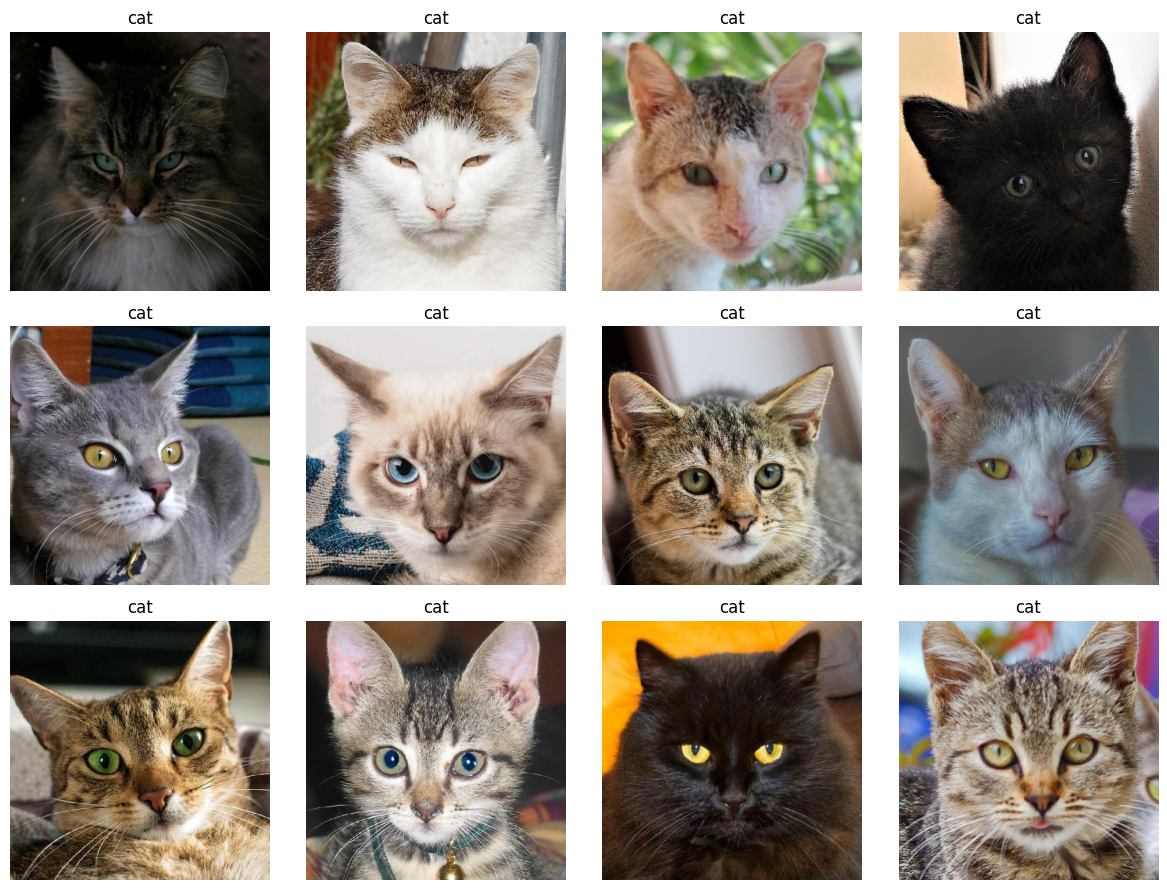

In [6]:

sample_dataset = datasets.ImageFolder(TRAIN_PATH)

class_names = sample_dataset.classes
print("Classes:", class_names)
print("Class mapping:", sample_dataset.class_to_idx)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for i, ax in enumerate(axes.flat):
    image, label = sample_dataset[i * 100]
    ax.imshow(image)
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [7]:

IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Read labels for stratified splitting
base_dataset = datasets.ImageFolder(TRAIN_PATH)
labels = base_dataset.targets
indices = np.arange(len(labels))

train_indices, valid_indices = train_test_split(
    indices,
    test_size=0.15,
    random_state=SEED,
    stratify=labels
)

# Separate datasets so validation has no random augmentation
train_full = datasets.ImageFolder(
    TRAIN_PATH, transform=train_transform
)

valid_full = datasets.ImageFolder(
    TRAIN_PATH, transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    TEST_PATH, transform=eval_transform
)

train_dataset = Subset(train_full, train_indices)
valid_dataset = Subset(valid_full, valid_indices)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Test images:", len(test_dataset))
print("Classes:", class_names)


Training images: 12435
Validation images: 2195
Test images: 1500
Classes: ['cat', 'dog', 'wild']


In [8]:

class CustomCNN(nn.Module):
    def __init__(self, num_classes=3):
        super(CustomCNN, self).__init__()

        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


cnn_model = CustomCNN(num_classes=len(class_names)).to(DEVICE)

print(cnn_model)
print(
    "Trainable parameters:",
    sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)
)


CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)

In [9]:

def train_model(model, train_loader, valid_loader,
                model_name, epochs=5, learning_rate=0.001):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=1e-4
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=2
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(DEVICE.type == "cuda")
    )

    best_accuracy = 0.0
    best_weights = copy.deepcopy(model.state_dict())

    history = {
        "train_loss": [],
        "valid_loss": [],
        "train_accuracy": [],
        "valid_accuracy": []
    }

    start_time = time.time()

    for epoch in range(epochs):

        # Training
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type=DEVICE.type,
                enabled=(DEVICE.type == "cuda")
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_accuracy = correct / total

        # Validation
        model.eval()
        valid_loss_total = 0.0
        valid_correct = 0
        valid_total = 0

        with torch.no_grad():
            for images, labels in valid_loader:
                images = images.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)

                with torch.autocast(
                    device_type=DEVICE.type,
                    enabled=(DEVICE.type == "cuda")
                ):
                    outputs = model(images)
                    loss = criterion(outputs, labels)

                valid_loss_total += loss.item() * images.size(0)

                predictions = outputs.argmax(dim=1)
                valid_correct += (predictions == labels).sum().item()
                valid_total += labels.size(0)

        valid_loss = valid_loss_total / valid_total
        valid_accuracy = valid_correct / valid_total

        scheduler.step(valid_accuracy)

        history["train_loss"].append(train_loss)
        history["valid_loss"].append(valid_loss)
        history["train_accuracy"].append(train_accuracy)
        history["valid_accuracy"].append(valid_accuracy)

        print(
            f"{model_name} | Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Loss: {valid_loss:.4f} | "
            f"Val Acc: {valid_accuracy:.4f}"
        )

        if valid_accuracy > best_accuracy:
            best_accuracy = valid_accuracy
            best_weights = copy.deepcopy(model.state_dict())

            torch.save(
                best_weights,
                f"/kaggle/working/{model_name}_best.pth"
            )

    model.load_state_dict(best_weights)

    print(f"\nBest validation accuracy: {best_accuracy:.4f}")
    print(f"Training time: {(time.time()-start_time)/60:.2f} minutes")

    return model, history


In [10]:

cnn_model, cnn_history = train_model(
    model=cnn_model,
    train_loader=train_loader,
    valid_loader=valid_loader,
    model_name="CustomCNN",
    epochs=5,
    learning_rate=0.001
)


CustomCNN | Epoch 1/5 | Train Loss: 0.7320 | Train Acc: 0.6637 | Val Loss: 0.8599 | Val Acc: 0.6497
CustomCNN | Epoch 2/5 | Train Loss: 0.4988 | Train Acc: 0.8034 | Val Loss: 0.4243 | Val Acc: 0.8319
CustomCNN | Epoch 3/5 | Train Loss: 0.4108 | Train Acc: 0.8477 | Val Loss: 0.4461 | Val Acc: 0.8146
CustomCNN | Epoch 4/5 | Train Loss: 0.3410 | Train Acc: 0.8706 | Val Loss: 0.4912 | Val Acc: 0.8150
CustomCNN | Epoch 5/5 | Train Loss: 0.2926 | Train Acc: 0.8892 | Val Loss: 0.5370 | Val Acc: 0.7845

Best validation accuracy: 0.8319
Training time: 12.40 minutes


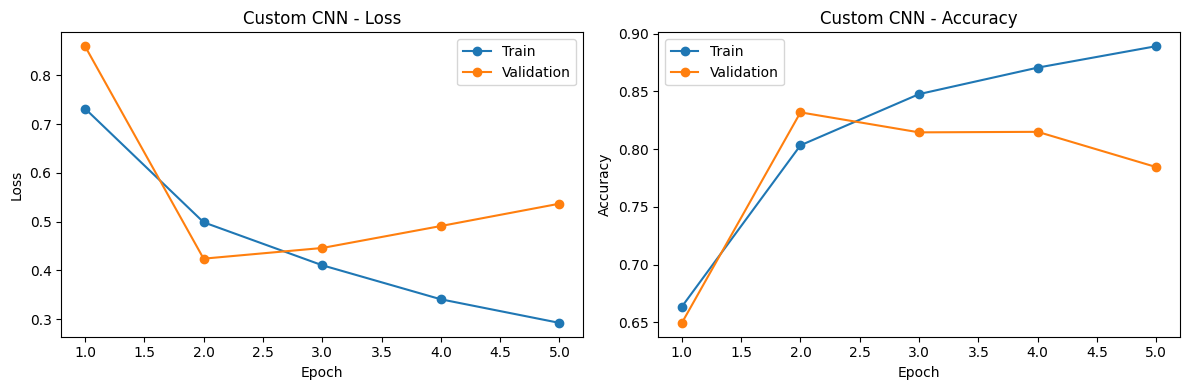

In [11]:

def plot_history(history, model_name):

    epochs = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["train_loss"], marker="o", label="Train")
    plt.plot(epochs, history["valid_loss"], marker="o", label="Validation")
    plt.title(f"{model_name} - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["train_accuracy"], marker="o", label="Train")
    plt.plot(epochs, history["valid_accuracy"], marker="o", label="Validation")
    plt.title(f"{model_name} - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.tight_layout()
    plt.show()


plot_history(cnn_history, "Custom CNN")


In [12]:

try:
    weights = models.ResNet18_Weights.DEFAULT
    resnet_model = models.resnet18(weights=weights)
    print("ImageNet pretrained weights loaded successfully.")

except Exception as e:
    print("Could not download pretrained weights:", e)
    print("Using ResNet18 without pretrained weights.")
    resnet_model = models.resnet18(weights=None)

# Replace the final classification layer
num_features = resnet_model.fc.in_features

resnet_model.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(num_features, len(class_names))
)

resnet_model = resnet_model.to(DEVICE)

print(resnet_model.fc)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 174MB/s] 


ImageNet pretrained weights loaded successfully.
Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=512, out_features=3, bias=True)
)


In [13]:

resnet_model, resnet_history = train_model(
    model=resnet_model,
    train_loader=train_loader,
    valid_loader=valid_loader,
    model_name="ResNet18",
    epochs=5,
    learning_rate=0.0001
)


ResNet18 | Epoch 1/5 | Train Loss: 0.0441 | Train Acc: 0.9853 | Val Loss: 0.0120 | Val Acc: 0.9968
ResNet18 | Epoch 2/5 | Train Loss: 0.0119 | Train Acc: 0.9968 | Val Loss: 0.0111 | Val Acc: 0.9968
ResNet18 | Epoch 3/5 | Train Loss: 0.0060 | Train Acc: 0.9986 | Val Loss: 0.0150 | Val Acc: 0.9950
ResNet18 | Epoch 4/5 | Train Loss: 0.0073 | Train Acc: 0.9973 | Val Loss: 0.0099 | Val Acc: 0.9968
ResNet18 | Epoch 5/5 | Train Loss: 0.0035 | Train Acc: 0.9989 | Val Loss: 0.0072 | Val Acc: 0.9982

Best validation accuracy: 0.9982
Training time: 5.26 minutes


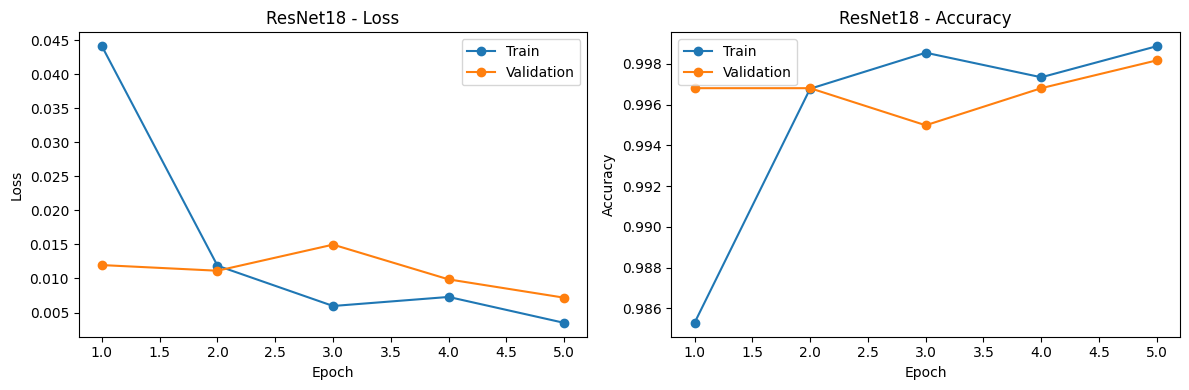

In [14]:

plot_history(resnet_history, "ResNet18")



Evaluation: Custom CNN
Accuracy : 0.8393
Precision: 0.8636
Recall   : 0.8393
Macro F1 : 0.8404

Classification Report:
              precision    recall  f1-score   support

         cat       0.92      0.78      0.85       500
         dog       0.72      0.97      0.83       500
        wild       0.95      0.76      0.85       500

    accuracy                           0.84      1500
   macro avg       0.86      0.84      0.84      1500
weighted avg       0.86      0.84      0.84      1500



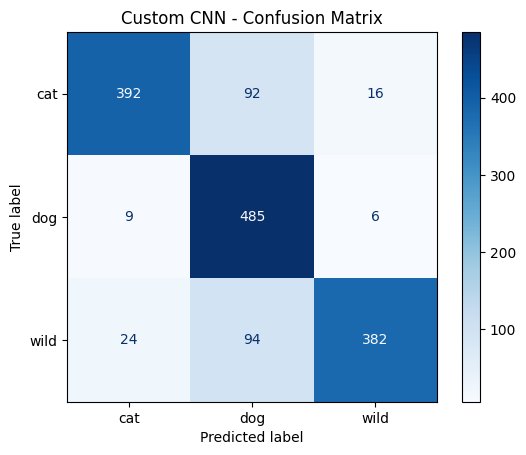


Evaluation: ResNet18
Accuracy : 0.9973
Precision: 0.9974
Recall   : 0.9973
Macro F1 : 0.9973

Classification Report:
              precision    recall  f1-score   support

         cat       1.00      1.00      1.00       500
         dog       1.00      0.99      1.00       500
        wild       0.99      1.00      1.00       500

    accuracy                           1.00      1500
   macro avg       1.00      1.00      1.00      1500
weighted avg       1.00      1.00      1.00      1500



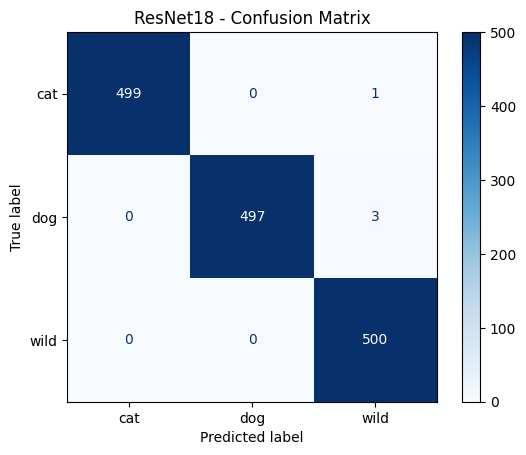

In [15]:

def evaluate_model(model, test_loader, model_name):

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in test_loader:

            images = images.to(DEVICE)

            with torch.autocast(
                device_type=DEVICE.type,
                enabled=(DEVICE.type == "cuda")
            ):
                outputs = model(images)

            predictions = outputs.argmax(dim=1).cpu().numpy()

            all_predictions.extend(predictions)
            all_labels.extend(labels.numpy())

    accuracy = accuracy_score(all_labels, all_predictions)
    precision = precision_score(
        all_labels, all_predictions, average="macro", zero_division=0
    )
    recall = recall_score(
        all_labels, all_predictions, average="macro", zero_division=0
    )
    f1 = f1_score(
        all_labels, all_predictions, average="macro", zero_division=0
    )

    print(f"\n{'='*45}")
    print(f"Evaluation: {model_name}")
    print(f"{'='*45}")

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"Macro F1 : {f1:.4f}")

    print("\nClassification Report:")
    print(
        classification_report(
            all_labels,
            all_predictions,
            target_names=class_names,
            zero_division=0
        )
    )

    cm = confusion_matrix(all_labels, all_predictions)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    display.plot(cmap="Blues", values_format="d")
    plt.title(f"{model_name} - Confusion Matrix")
    plt.show()

    return {
        "model": model_name,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "macro_f1": f1
    }


cnn_results = evaluate_model(
    cnn_model, test_loader, "Custom CNN"
)

resnet_results = evaluate_model(
    resnet_model, test_loader, "ResNet18"
)


FINAL MODEL COMPARISON


,model,accuracy,precision,recall,macro_f1
0,Custom CNN,0.8393,0.8636,0.8393,0.8404
1,ResNet18,0.9973,0.9974,0.9973,0.9973


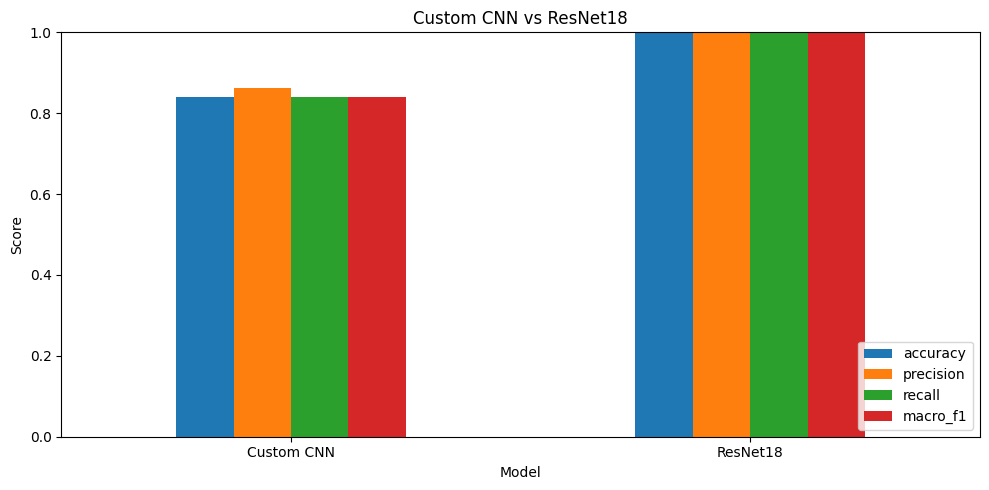

In [16]:

import pandas as pd

results_df = pd.DataFrame([
    cnn_results,
    resnet_results
])

print("FINAL MODEL COMPARISON")
display(results_df.round(4))

metrics = ["accuracy", "precision", "recall", "macro_f1"]

results_df.set_index("model")[metrics].plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Custom CNN vs ResNet18")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


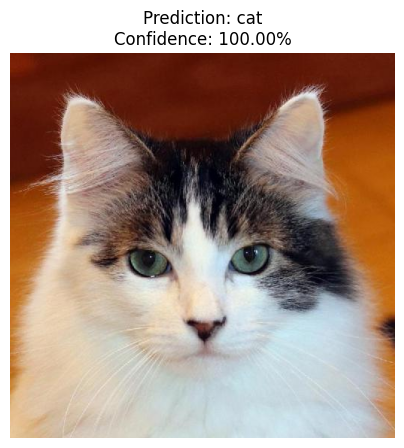

Predicted class: cat
Confidence: 100.00%


In [17]:

from PIL import Image

def predict_image(image_path, model):

    image = Image.open(image_path).convert("RGB")
    image_tensor = eval_transform(image).unsqueeze(0).to(DEVICE)

    model.eval()

    with torch.no_grad():
        with torch.autocast(
            device_type=DEVICE.type,
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = model(image_tensor)

        probabilities = torch.softmax(outputs, dim=1)[0]

    predicted_index = probabilities.argmax().item()
    predicted_class = class_names[predicted_index]
    confidence = probabilities[predicted_index].item() * 100

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.axis("off")
    plt.show()

    print("Predicted class:", predicted_class)
    print(f"Confidence: {confidence:.2f}%")

# Example: test the first image in the official validation folder
sample_path = os.path.join(
    TEST_PATH,
    class_names[0],
    os.listdir(os.path.join(TEST_PATH, class_names[0]))[0]
)

predict_image(sample_path, resnet_model)


In [18]:

import json

# Save both models
torch.save(
    cnn_model.state_dict(),
    "/kaggle/working/CustomCNN_final.pth"
)

torch.save(
    resnet_model.state_dict(),
    "/kaggle/working/ResNet18_final.pth"
)

# Save class names and image configuration
with open("/kaggle/working/class_names.json", "w") as f:
    json.dump({
        "classes": class_names,
        "image_size": IMAGE_SIZE
    }, f, indent=4)

# Save comparison metrics
results_df.to_csv(
    "/kaggle/working/model_comparison.csv",
    index=False
)

print("Project files saved successfully!")

print(os.listdir("/kaggle/working"))


Project files saved successfully!
['class_names.json', 'CustomCNN_best.pth', 'ResNet18_final.pth', 'ResNet18_best.pth', 'model_comparison.csv', '.virtual_documents', 'CustomCNN_final.pth']
